# Comparação de Otimizadores em Redes Neurais para Estimativa de Consumo de Combustível

> Alan Hoffmann Dos Santos

Neste notebook será comparado o desempenho de diferentes **otimizadores** no treinamento da rede neural de **regressão** construída em aula, que estima o consumo de combustível em **km/L**.

O conjunto `mpg_limpo.csv` possui 392 registros e, entre suas variáveis, estão `horsepower`, `acceleration`, `weight_kg`, `volume_cm3` e `km_l`. A variável `km_l` será utilizada como variável-alvo.

Para que a comparação seja justa, são mantidos fixos os dados, a divisão em treinamento/validação/teste, a padronização, a arquitetura (4 → 32 → 16 → 1), a função de perda (MSE), o tamanho do lote e o critério de parada. **Somente o otimizador e sua taxa de aprendizado mudam.**

Otimizadores comparados: SGD, SGD + Momentum, Adagrad, RMSprop, Adadelta, Adam, Nadam e AdamW.

Objetivos:
- carregar os dados e repetir a preparação do notebook de aula;
- definir uma linha de base com regressão linear;
- comparar os otimizadores com a mesma taxa de aprendizado (Experimento 1);
- buscar a melhor taxa de aprendizado de cada otimizador pela validação (Experimento 2);
- repetir o treinamento com 5 sementes para verificar a robustez (Experimento 3);
- avaliar o otimizador escolhido no conjunto de teste com MAE, RMSE e R².

O conjunto de teste não participa de nenhuma escolha e é utilizado somente na avaliação final.


In [1]:
import os, time, random, warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
def fixar_semente(seed):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
fixar_semente(SEED)

sns.set_theme(style='whitegrid')
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 1. Carregamento e preparação dos dados

Mesmo fluxo do notebook da aula: 4 entradas numéricas, alvo `km_l`, divisão 70/15/15 e padronização com média e desvio **apenas do treino**.

In [2]:
# No Colab: faça upload de mpg_limpo.csv (ícone de pasta à esquerda)
CAMINHO = '/content/mpg_limpo.csv' if os.path.exists('/content/mpg_limpo.csv') else 'mpg_limpo.csv'
df = pd.read_csv(CAMINHO)

FEATURES = ['acceleration', 'horsepower', 'weight_kg', 'volume_cm3']
TARGET = 'km_l'

print(f'{df.shape[0]} linhas x {df.shape[1]} colunas | ausentes: {df.isna().sum().sum()} | duplicados: {df.duplicated().sum()}')
df[FEATURES + [TARGET]].describe().T.round(2)

392 linhas x 9 colunas | ausentes: 0 | duplicados: 0


,count,mean,std,min,25%,50%,75%,max
acceleration,392.0,15.54,2.76,8.00,13.78,15.50,17.02,24.80
horsepower,392.0,104.47,38.49,46.00,75.00,93.50,126.00,230.00
weight_kg,392.0,1350.61,385.28,731.64,1009.36,1271.65,1639.62,2331.46
volume_cm3,392.0,3185.85,1714.81,1114.32,1720.65,2474.45,4518.74,7456.13
km_l,392.0,9.97,3.32,3.83,7.23,9.67,12.33,19.81


In [3]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED)

media, desvio = X_train.mean(), X_train.std().replace(0, 1)
X_train_s = ((X_train - media) / desvio).values.astype('float32')
X_val_s   = ((X_val   - media) / desvio).values.astype('float32')
X_test_s  = ((X_test  - media) / desvio).values.astype('float32')
y_train_v, y_val_v, y_test_v = [v.values.astype('float32') for v in (y_train, y_val, y_test)]

print(f'Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}')

Treino: 274 | Validação: 59 | Teste: 59


### Linha de base: regressão linear

Antes de comparar otimizadores, vale saber quanto um modelo simples consegue. Se a rede neural não superar a regressão linear, não vale a pena o esforço.

In [4]:
lin = LinearRegression().fit(X_train_s, y_train_v)
p = lin.predict(X_test_s)
base = {'MAE': mean_absolute_error(y_test_v, p),
        'RMSE': mean_squared_error(y_test_v, p) ** 0.5,
        'R2': r2_score(y_test_v, p)}
print('Regressão linear (teste):', {k: round(v, 4) for k, v in base.items()})

Regressão linear (teste): {'MAE': 1.542, 'RMSE': 1.8131, 'R2': 0.632}


## 2. Os otimizadores

Todos atualizam os pesos $w$ na direção contrária ao gradiente $g = \nabla_w L$; a diferença está em **como** usam o histórico dos gradientes.

| Otimizador | Ideia principal | Regra (simplificada) |
|---|---|---|
| **SGD** | Passo fixo na direção do gradiente | $w \leftarrow w - \eta\, g$ |
| **SGD + Momentum** | Acumula uma "velocidade", atravessa platôs e amortece oscilações | $v \leftarrow \beta v - \eta g;\ w \leftarrow w + v$ |
| **Adagrad** | Taxa individual por peso, que diminui com a soma dos gradientes² | $w \leftarrow w - \frac{\eta}{\sqrt{\sum g^2}+\epsilon} g$ |
| **RMSprop** | Igual ao Adagrad, mas com **média móvel** de $g^2$ (a taxa não morre) | $s \leftarrow \rho s + (1-\rho) g^2;\ w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} g$ |
| **Adadelta** | Extensão do Adagrad que dispensa escolher a taxa (no Keras usa-se η≈1) | razão entre médias móveis de $\Delta w^2$ e $g^2$ |
| **Adam** | Momentum + RMSprop, com correção de viés | $m, v$ = médias de $g$ e $g^2$; $w \leftarrow w - \eta \frac{\hat m}{\sqrt{\hat v}+\epsilon}$ |
| **Nadam** | Adam com momentum de Nesterov ("olha à frente") | — |
| **AdamW** | Adam com *weight decay* desacoplado (regularização) | Adam $- \eta \lambda w$ |

**Referências**
- RUDER, S. *An overview of gradient descent optimization algorithms*. arXiv:1609.04747, 2016.
- KINGMA, D. P.; BA, J. *Adam: A Method for Stochastic Optimization*. ICLR, 2015.
- GOODFELLOW, I.; BENGIO, Y.; COURVILLE, A. *Deep Learning*. MIT Press, 2016 (cap. 8).
- LOSHCHILOV, I.; HUTTER, F. *Decoupled Weight Decay Regularization*. ICLR, 2019.
- KERAS. *Optimizers*. https://keras.io/api/optimizers/

In [5]:
def criar_otimizador(nome, lr):
    o = tf.keras.optimizers
    return {
        'SGD':          lambda: o.SGD(learning_rate=lr),
        'SGD+Momentum': lambda: o.SGD(learning_rate=lr, momentum=0.9),
        'Adagrad':      lambda: o.Adagrad(learning_rate=lr),
        'RMSprop':      lambda: o.RMSprop(learning_rate=lr),
        'Adadelta':     lambda: o.Adadelta(learning_rate=lr),
        'Adam':         lambda: o.Adam(learning_rate=lr),
        'Nadam':        lambda: o.Nadam(learning_rate=lr),
        'AdamW':        lambda: o.AdamW(learning_rate=lr, weight_decay=1e-4),
    }[nome]()

OTIMIZADORES = ['SGD', 'SGD+Momentum', 'Adagrad', 'RMSprop', 'Adadelta', 'Adam', 'Nadam', 'AdamW']

def criar_modelo(seed=SEED):
    # Mesma arquitetura da aula: 4 -> 32 -> 16 -> 1
    fixar_semente(seed)
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(len(FEATURES),)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1)
    ])

def treinar(nome, lr, seed=SEED, epocas=300):
    # Treina um modelo e devolve histórico + métricas de validação e de teste
    modelo = criar_modelo(seed)
    modelo.compile(optimizer=criar_otimizador(nome, lr), loss='mse',
                   metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae')])
    cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
          tf.keras.callbacks.TerminateOnNaN()]
    t0 = time.time()
    h = modelo.fit(X_train_s, y_train_v, validation_data=(X_val_s, y_val_v),
                   epochs=epocas, batch_size=32, shuffle=True, callbacks=cb, verbose=0)
    tempo = time.time() - t0

    val_loss = np.array(h.history['val_loss'], dtype=float)
    if not np.all(np.isfinite(val_loss)):      # divergiu (taxa grande demais)
        return {'otimizador': nome, 'lr': lr, 'seed': seed, 'val_rmse': np.inf, 'divergiu': True,
                'historico': h.history, 'modelo': None, 'tempo_s': tempo, 'epocas': len(val_loss)}

    melhor_ep = int(np.argmin(val_loss)) + 1
    p_test = modelo.predict(X_test_s, verbose=0).ravel()
    return {'otimizador': nome, 'lr': lr, 'seed': seed, 'divergiu': False,
            'val_rmse': float(np.sqrt(val_loss.min())),
            'test_mae': mean_absolute_error(y_test_v, p_test),
            'test_rmse': mean_squared_error(y_test_v, p_test) ** 0.5,
            'test_r2': r2_score(y_test_v, p_test),
            'melhor_epoca': melhor_ep, 'epocas': len(val_loss), 'tempo_s': tempo,
            'historico': h.history, 'modelo': modelo, 'pred_test': p_test}

## 3. Experimento 1 — todos com a mesma taxa de aprendizado (η = 0,001)

É a comparação "ingênua": usa a taxa do notebook da aula para todos. Ela mostra **velocidade de convergência**, mas é injusta com otimizadores que precisam de taxas maiores (SGD, Adagrad, Adadelta).

In [6]:
exp1 = {}
for nome in OTIMIZADORES:
    exp1[nome] = treinar(nome, 1e-3)
    r = exp1[nome]
    print(f"{nome:13s} val RMSE = {r['val_rmse']:.3f} km/L | épocas = {r['epocas']:3d} | {r['tempo_s']:.1f}s")

SGD           val RMSE = 1.716 km/L | épocas = 113 | 9.0s


SGD+Momentum  val RMSE = 1.671 km/L | épocas =  28 | 2.6s


Adagrad       val RMSE = 7.633 km/L | épocas = 300 | 24.8s


RMSprop       val RMSE = 1.690 km/L | épocas = 149 | 11.9s


Adadelta      val RMSE = 10.872 km/L | épocas = 300 | 25.5s


Adam          val RMSE = 1.718 km/L | épocas = 300 | 29.9s


Nadam         val RMSE = 1.710 km/L | épocas = 300 | 51.5s


AdamW         val RMSE = 1.718 km/L | épocas = 300 | 43.9s


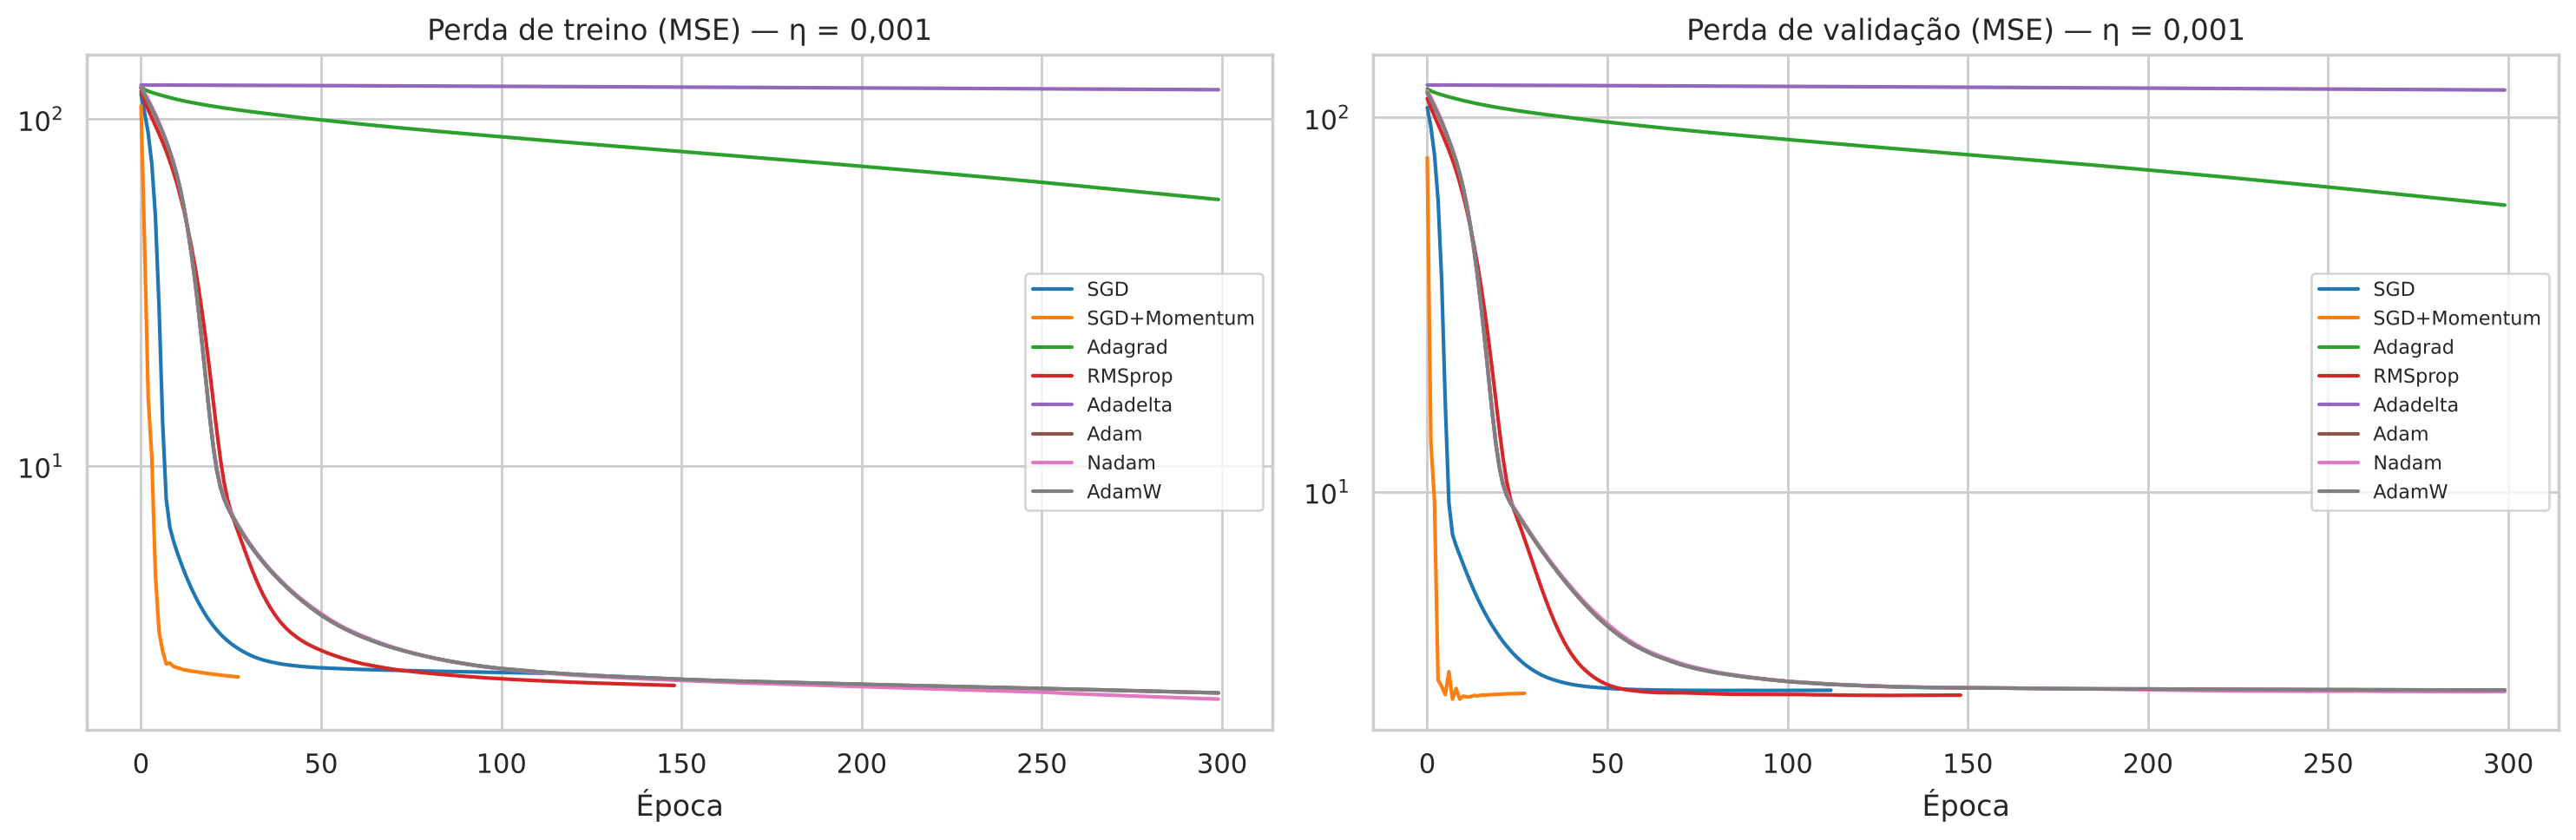

In [7]:
cores = dict(zip(OTIMIZADORES, sns.color_palette('tab10', len(OTIMIZADORES))))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for nome, r in exp1.items():
    axes[0].plot(r['historico']['loss'], color=cores[nome], label=nome)
    axes[1].plot(r['historico']['val_loss'], color=cores[nome], label=nome)
for ax, t in zip(axes, ['Perda de treino (MSE)', 'Perda de validação (MSE)']):
    ax.set_yscale('log'); ax.set_xlabel('Época'); ax.set_title(t + ' — η = 0,001'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura (resultado surpreendente):** com η = 0,001, quem converge mais rápido é o **SGD + Momentum** (~28 épocas) e depois o **SGD** puro. **Adam, Nadam e AdamW** usam todas as 300 épocas e ainda estão descendo devagar. **Adagrad e Adadelta praticamente não aprendem** (RMSE de validação de 7,6 e 10,9 km/L).

Isso **não** quer dizer que Adagrad ou Adam sejam ruins: η = 0,001 é pequeno demais para eles. Comparar todos com a mesma taxa é injusto — por isso o Experimento 2 busca a melhor taxa de cada um.

## 4. Experimento 2 — busca da melhor taxa para cada otimizador

Cada otimizador é testado em 5 taxas (0,0001 a 1). A escolha é feita pelo **RMSE de validação** — o teste continua guardado.

In [8]:
TAXAS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
linhas = []
t0 = time.time()
for nome in OTIMIZADORES:
    for lr in TAXAS:
        r = treinar(nome, lr)
        linhas.append({'otimizador': nome, 'lr': lr, 'val_rmse': r['val_rmse'], 'épocas': r['epocas']})
    print(f'{nome:13s} ok ({time.time() - t0:.0f}s)')
grade = pd.DataFrame(linhas)

SGD           ok (88s)


SGD+Momentum  ok (127s)


Adagrad       ok (292s)


RMSprop       ok (368s)


Adadelta      ok (546s)


Adam          ok (641s)


Nadam         ok (745s)


AdamW         ok (843s)


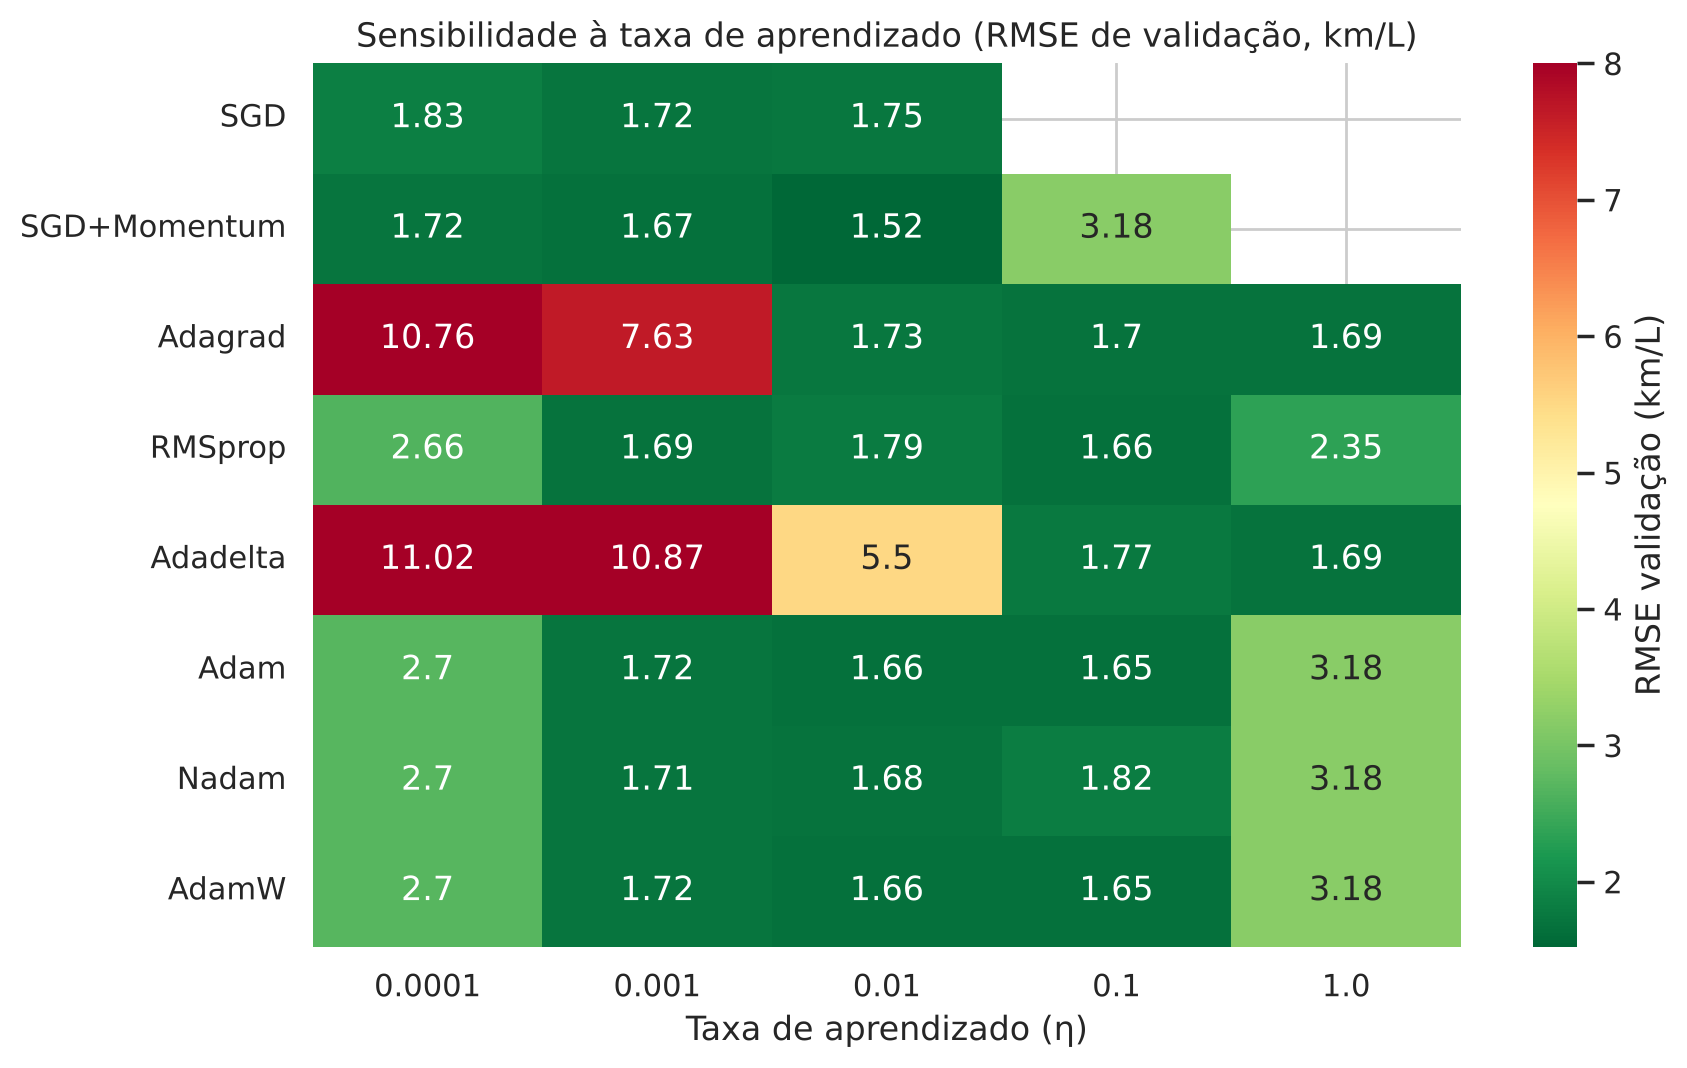

,melhor η,RMSE val
SGD,0.001,1.7161
SGD+Momentum,0.010,1.5244
Adagrad,1.000,1.6864
RMSprop,0.100,1.6634
Adadelta,1.000,1.6905
Adam,0.100,1.6524
Nadam,0.010,1.6809
AdamW,0.100,1.6526


In [9]:
mapa = grade.pivot(index='otimizador', columns='lr', values='val_rmse').loc[OTIMIZADORES]
plt.figure(figsize=(9, 5.5))
sns.heatmap(mapa.replace(np.inf, np.nan).clip(upper=8), annot=mapa.round(2).astype(str).replace('inf', 'diverg.'),
            fmt='', cmap='RdYlGn_r', cbar_kws={'label': 'RMSE validação (km/L)'})
plt.title('Sensibilidade à taxa de aprendizado (RMSE de validação, km/L)')
plt.xlabel('Taxa de aprendizado (η)'); plt.ylabel('')
plt.tight_layout(); plt.show()

MELHOR_LR = grade.loc[grade.groupby('otimizador')['val_rmse'].idxmin()].set_index('otimizador')['lr'].to_dict()
pd.DataFrame({'melhor η': MELHOR_LR,
              'RMSE val': grade.groupby('otimizador')['val_rmse'].min()}).loc[OTIMIZADORES].round(4)

**Leitura do mapa de calor** (células em branco = o treino **divergiu**, a perda virou infinito):
- **SGD** só funciona com taxas pequenas (≤ 0,01); com 0,1 ou 1 explode. Com momentum, a melhor taxa é 0,01 e o limite é 0,1.
- **Adagrad e Adadelta** são o oposto: só funcionam com taxas grandes (0,1 a 1), porque reduzem o passo efetivo ao longo do treino.
- **Adam, AdamW e RMSprop** dão bons resultados numa faixa larga (0,001 a 0,1) — são os mais **fáceis de ajustar**.
- Taxa grande demais (η = 1) atrapalha todos os otimizadores com momentum.

## 5. Experimento 3 — robustez (5 sementes na melhor taxa)

Um único treino pode ter sorte ou azar com a inicialização dos pesos. Repetimos cada otimizador com **5 sementes diferentes** e reportamos **média ± desvio padrão**. Aqui, pela primeira vez, olhamos o **teste**.

In [10]:
SEMENTES = [0, 1, 2, 3, 4]
runs = []
for nome in OTIMIZADORES:
    for s in SEMENTES:
        runs.append(treinar(nome, MELHOR_LR[nome], seed=s))
    print(f'{nome:13s} ok')

res = pd.DataFrame([{k: v for k, v in r.items() if k not in ('historico', 'modelo', 'pred_test')} for r in runs])
resumo = (res.groupby('otimizador')
             .agg(lr=('lr', 'first'),
                  val_RMSE=('val_rmse', 'mean'),
                  teste_MAE=('test_mae', 'mean'), teste_MAE_dp=('test_mae', 'std'),
                  teste_RMSE=('test_rmse', 'mean'), teste_RMSE_dp=('test_rmse', 'std'),
                  teste_R2=('test_r2', 'mean'),
                  melhor_epoca=('melhor_epoca', 'mean'), tempo_s=('tempo_s', 'mean'))
             .sort_values('val_RMSE'))
resumo.round(4)

SGD           ok


SGD+Momentum  ok


Adagrad       ok


RMSprop       ok


Adadelta      ok


Adam          ok


Nadam         ok


AdamW         ok


,lr,val_RMSE,teste_MAE,teste_MAE_dp,teste_RMSE,teste_RMSE_dp,teste_R2,melhor_epoca,tempo_s
otimizador,,,,,,,,,
Adam,0.100,1.6591,1.3531,0.0356,1.7109,0.0258,0.6723,9.2,2.9978
Adadelta,1.000,1.6595,1.4068,0.0636,1.7867,0.0758,0.6421,95.2,10.2864
Nadam,0.010,1.6606,1.4398,0.0238,1.8157,0.0352,0.6308,19.4,4.2290
AdamW,0.100,1.6610,1.3565,0.0235,1.7121,0.0227,0.6718,6.6,2.9807
SGD+Momentum,0.010,1.6671,1.3237,0.0191,1.6557,0.0351,0.6930,21.0,4.2317
SGD,0.001,1.6702,1.4279,0.0453,1.8013,0.0322,0.6367,122.0,12.2679
Adagrad,1.000,1.7419,1.4109,0.0967,1.7880,0.1056,0.6411,181.2,18.3936
RMSprop,0.100,1.8857,1.4983,0.4000,1.9022,0.4936,0.5731,15.0,3.5248


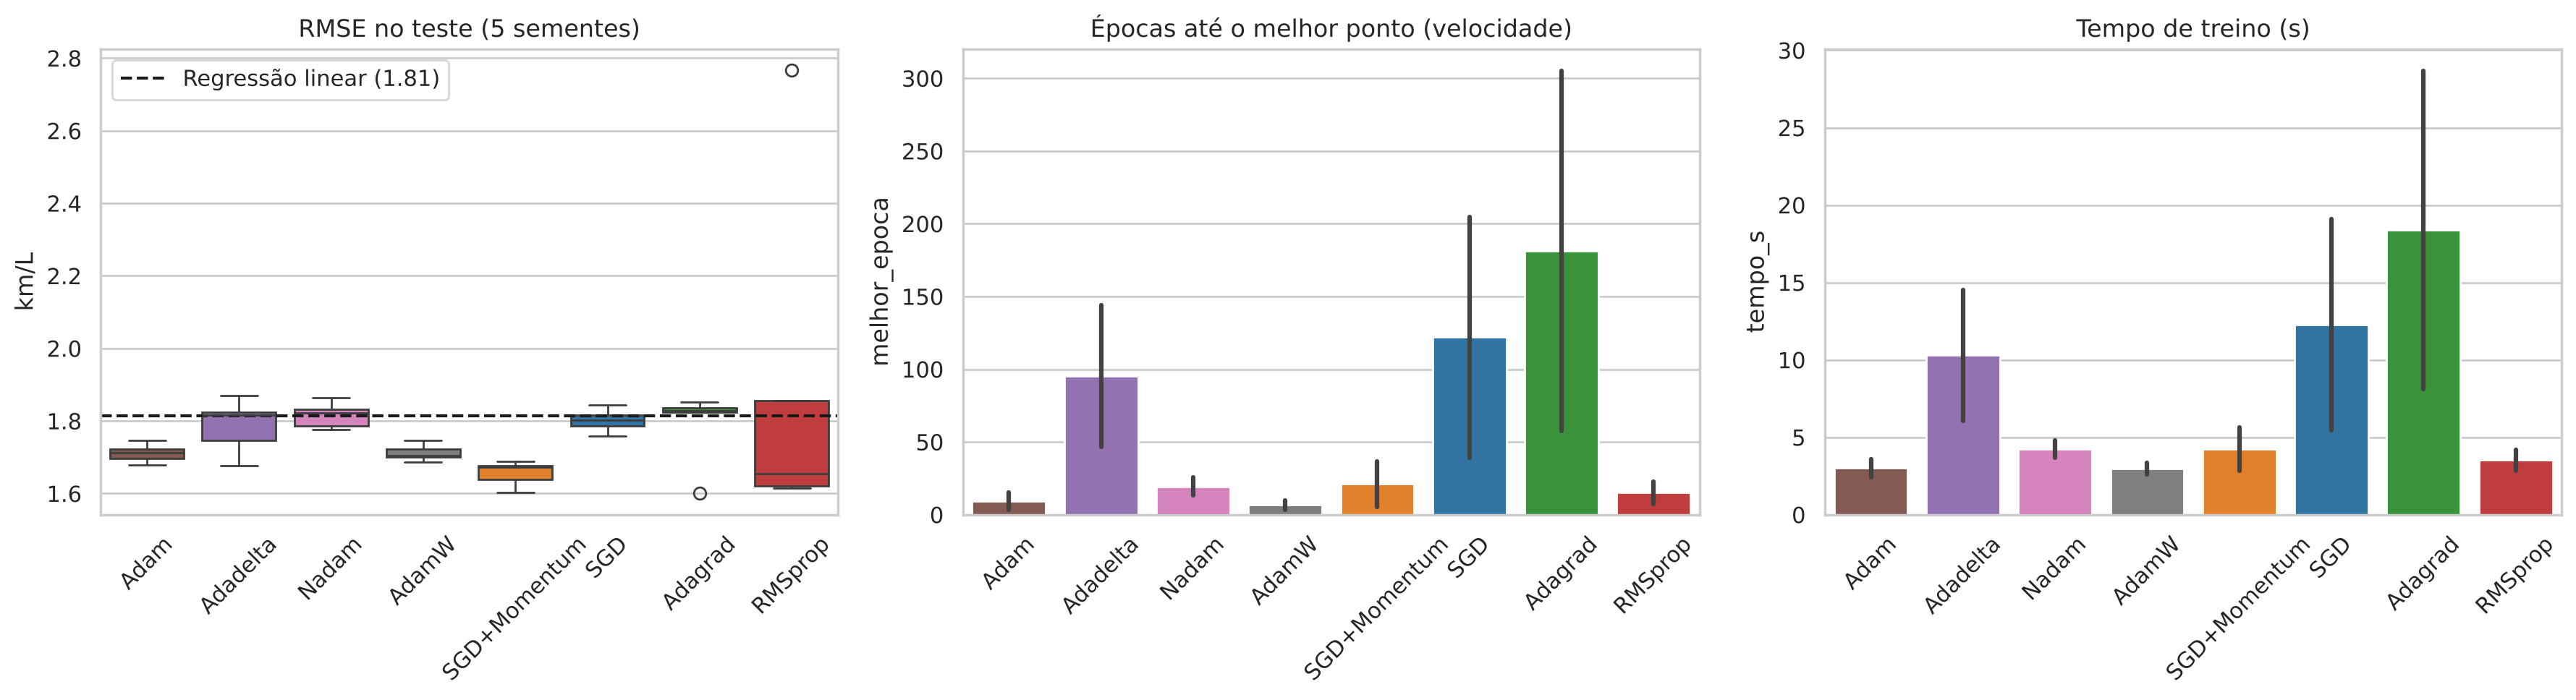

In [11]:
ordem = resumo.index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=res, x='otimizador', y='test_rmse', order=ordem, palette=cores, ax=axes[0])
axes[0].axhline(base['RMSE'], ls='--', c='k', label=f"Regressão linear ({base['RMSE']:.2f})"); axes[0].legend()
axes[0].set_title('RMSE no teste (5 sementes)'); axes[0].set_ylabel('km/L')
sns.barplot(data=res, x='otimizador', y='melhor_epoca', order=ordem, palette=cores, ax=axes[1], errorbar='sd')
axes[1].set_title('Épocas até o melhor ponto (velocidade)')
sns.barplot(data=res, x='otimizador', y='tempo_s', order=ordem, palette=cores, ax=axes[2], errorbar='sd')
axes[2].set_title('Tempo de treino (s)')
for ax in axes: ax.tick_params(axis='x', rotation=45); ax.set_xlabel('')
plt.tight_layout(); plt.show()

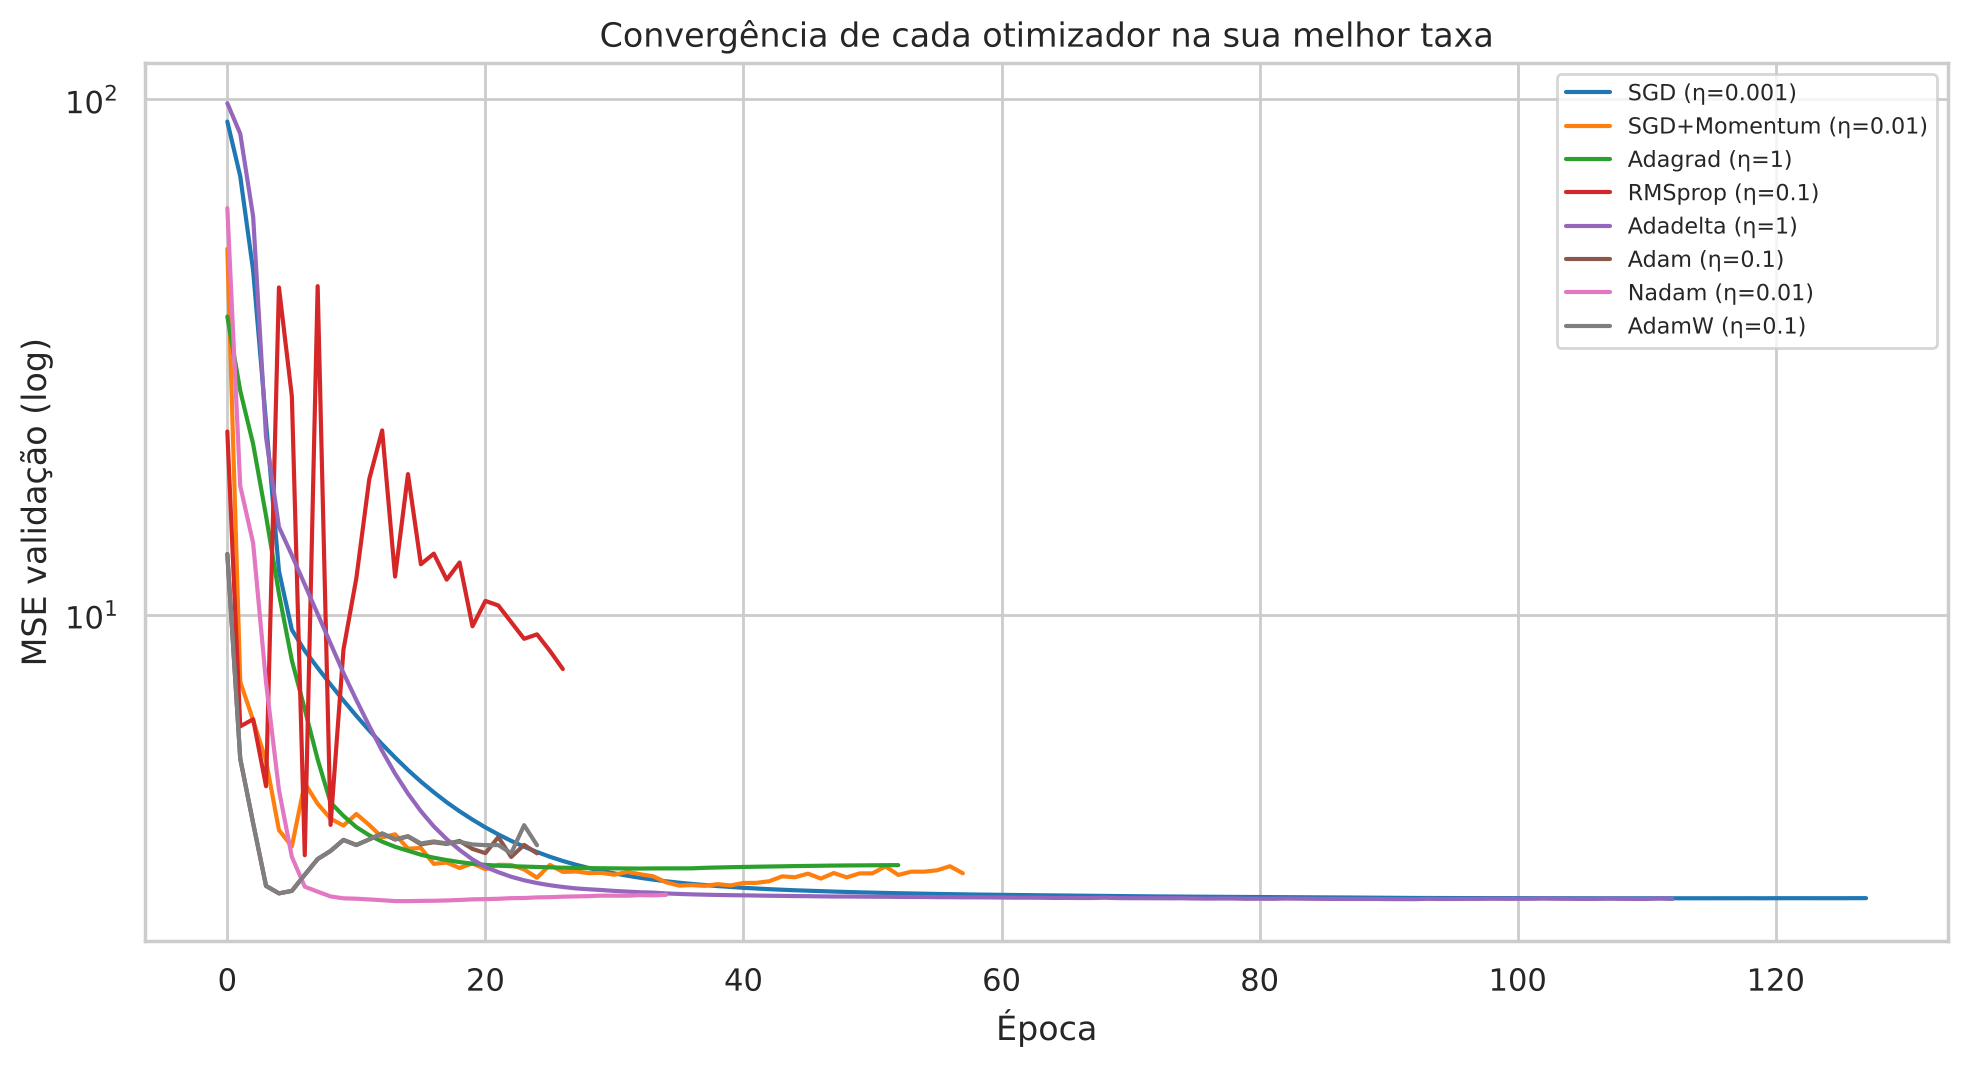

In [12]:
# Curvas de validação (semente 0) de cada otimizador na sua melhor taxa
plt.figure(figsize=(10, 5.5))
for r in runs:
    if r['seed'] == 0:
        plt.plot(r['historico']['val_loss'], color=cores[r['otimizador']],
                 label=f"{r['otimizador']} (η={r['lr']:g})")
plt.yscale('log'); plt.xlabel('Época'); plt.ylabel('MSE validação (log)')
plt.title('Convergência de cada otimizador na sua melhor taxa'); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Melhor modelo: real × previsto e resíduos

Vencedor (pela validação): Adam, η = 0.1, semente 3
Teste -> MAE = 1.299 km/L | RMSE = 1.678 km/L | R² = 0.685


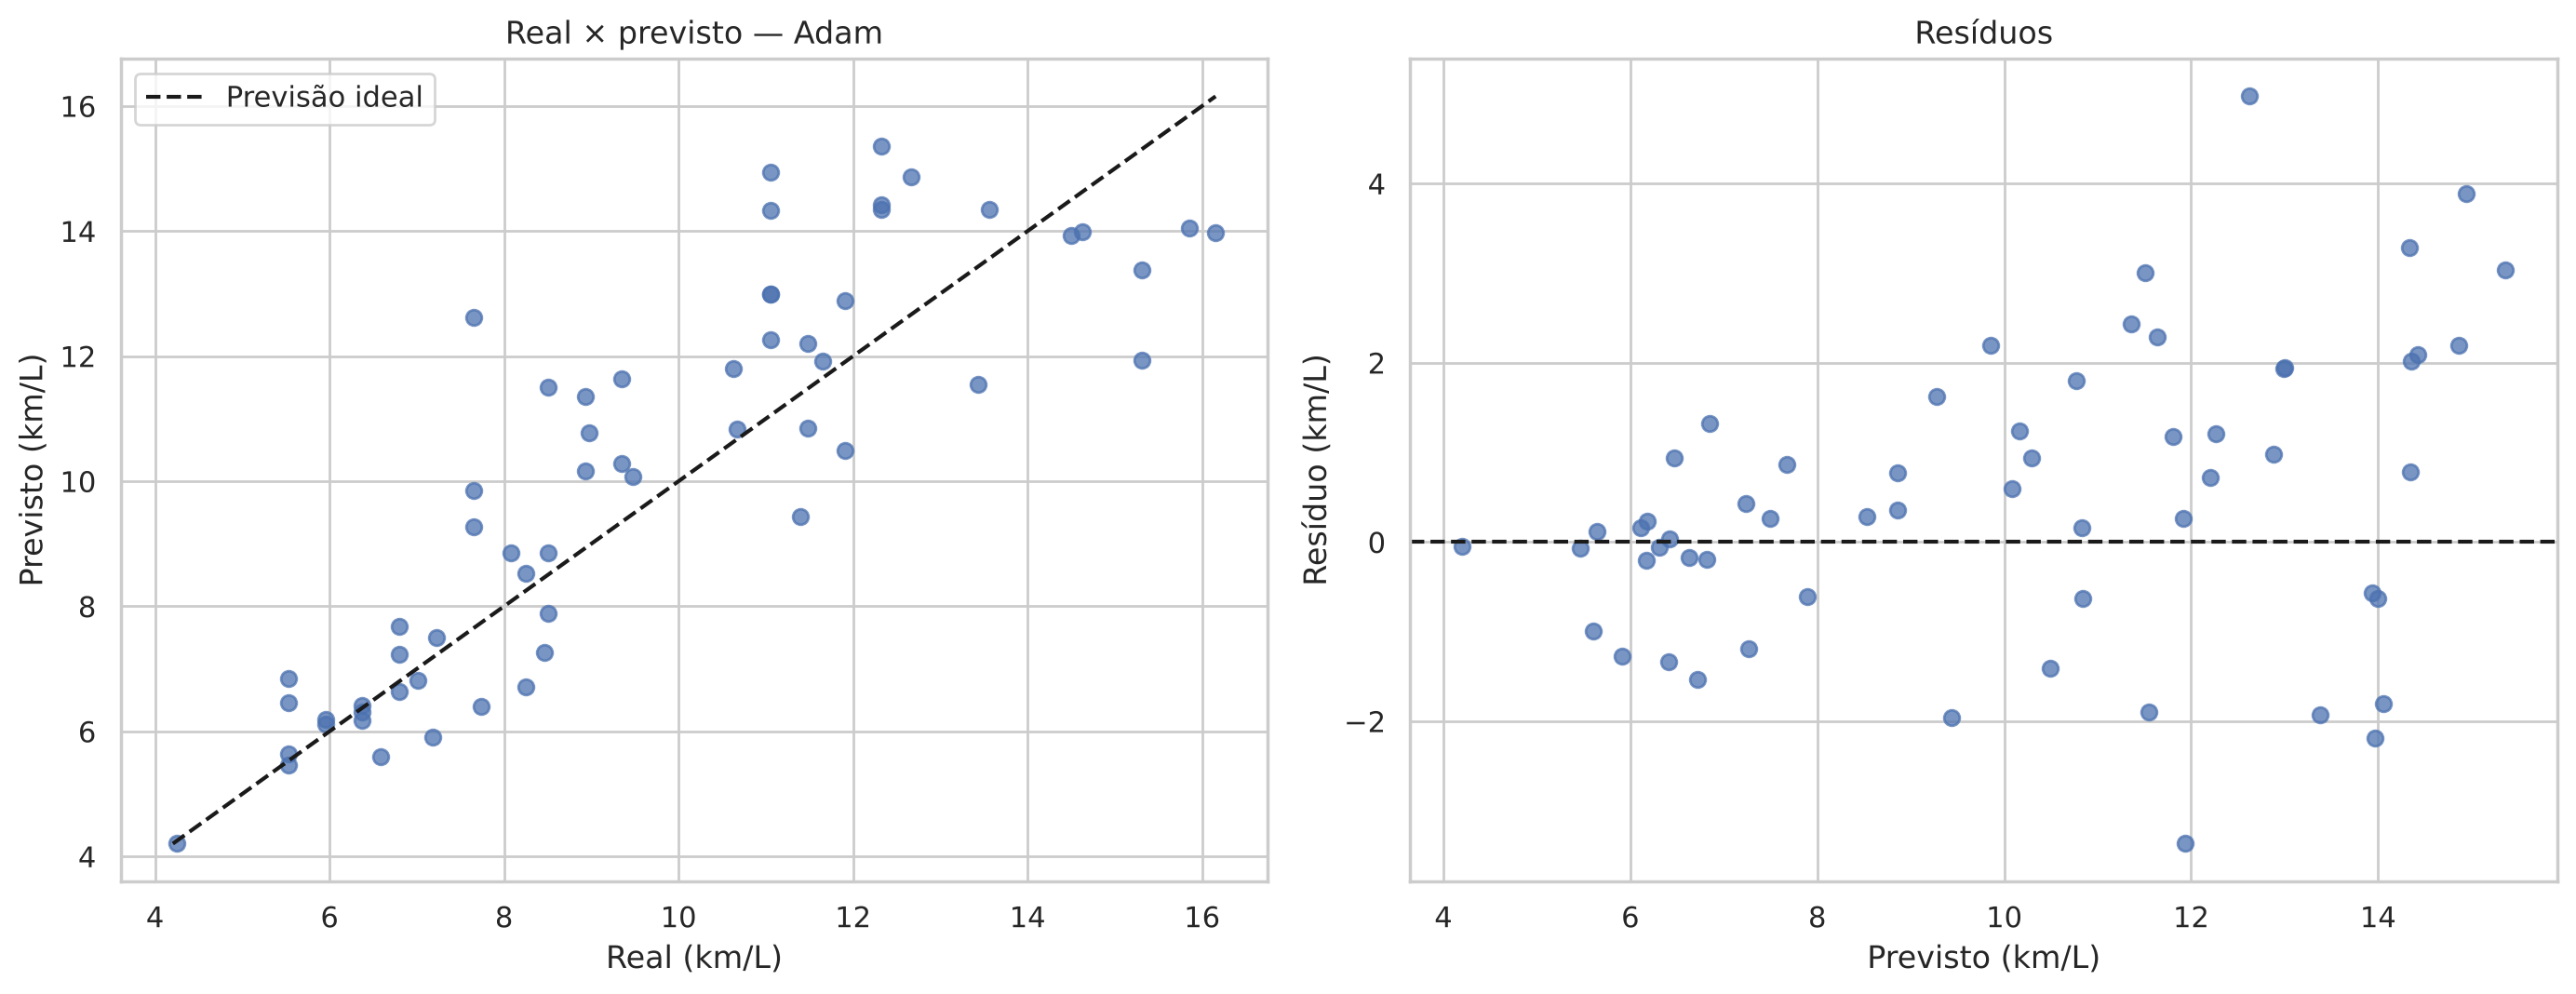

In [13]:
vencedor = resumo.index[0]
r_best = min([r for r in runs if r['otimizador'] == vencedor], key=lambda r: r['val_rmse'])
p = r_best['pred_test']
print(f"Vencedor (pela validação): {vencedor}, η = {r_best['lr']:g}, semente {r_best['seed']}")
print(f"Teste -> MAE = {r_best['test_mae']:.3f} km/L | RMSE = {r_best['test_rmse']:.3f} km/L | R² = {r_best['test_r2']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(y_test_v, p, alpha=0.75)
lim = [min(y_test_v.min(), p.min()), max(y_test_v.max(), p.max())]
axes[0].plot(lim, lim, '--k', label='Previsão ideal'); axes[0].legend()
axes[0].set_xlabel('Real (km/L)'); axes[0].set_ylabel('Previsto (km/L)'); axes[0].set_title(f'Real × previsto — {vencedor}')
axes[1].scatter(p, p - y_test_v, alpha=0.75); axes[1].axhline(0, ls='--', c='k')
axes[1].set_xlabel('Previsto (km/L)'); axes[1].set_ylabel('Resíduo (km/L)'); axes[1].set_title('Resíduos')
plt.tight_layout(); plt.show()

In [14]:
# Tabela final para o relatório/apresentação
tabela = resumo[['lr', 'teste_MAE', 'teste_RMSE', 'teste_RMSE_dp', 'teste_R2', 'melhor_epoca', 'tempo_s']].copy()
tabela.loc['Regressão linear (base)'] = [np.nan, base['MAE'], base['RMSE'], 0, base['R2'], np.nan, np.nan]
tabela.round(3).to_csv('comparacao_otimizadores.csv')
tabela.round(3)

,lr,teste_MAE,teste_RMSE,teste_RMSE_dp,teste_R2,melhor_epoca,tempo_s
otimizador,,,,,,,
Adam,0.100,1.353,1.711,0.026,0.672,9.2,2.998
Adadelta,1.000,1.407,1.787,0.076,0.642,95.2,10.286
Nadam,0.010,1.440,1.816,0.035,0.631,19.4,4.229
AdamW,0.100,1.356,1.712,0.023,0.672,6.6,2.981
SGD+Momentum,0.010,1.324,1.656,0.035,0.693,21.0,4.232
SGD,0.001,1.428,1.801,0.032,0.637,122.0,12.268
Adagrad,1.000,1.411,1.788,0.106,0.641,181.2,18.394
RMSprop,0.100,1.498,1.902,0.494,0.573,15.0,3.525
Regressão linear (base),NaN,1.542,1.813,0.000,0.632,NaN,NaN


## 7. Conclusão

Pontos importantes do experimento:

1. **A taxa de aprendizado importa mais do que o otimizador.** Com η = 0,001 para todos, Adagrad e Adadelta pareciam inúteis (RMSE 7,6 e 10,9 km/L); com a taxa certa, ficaram no mesmo nível dos outros (≈ 1,69 km/L na validação). Comparar otimizadores sem ajustar a taxa leva a conclusões erradas.
2. **Depois de ajustar a taxa, a precisão final é parecida** (RMSE de teste entre 1,66 e 1,82 km/L na maioria). As grandes diferenças estão na **velocidade** e na **estabilidade**:
   - **Adam e AdamW** chegam ao melhor ponto em **7–9 épocas (~3 s)**, com pouca variação entre sementes (RMSE teste 1,71 ± 0,03 km/L).
   - **SGD** precisa de ~120 épocas e **Adagrad** de ~180 — 10 a 20 vezes mais lentos.
   - **RMSprop** com η = 0,1 foi o melhor em uma semente, mas o **mais instável** em 5 sementes (desvio de 0,49 km/L; uma execução chegou a 2,77 km/L). Escolher pelo resultado de uma única execução é arriscado.
3. **Otimizador escolhido: Adam (η = 0,1)** — melhor RMSE médio de validação, mais rápido, estável e funciona numa faixa larga de taxas. O **SGD + Momentum** teve o melhor resultado no teste (RMSE 1,66 km/L, R² 0,69), mas como a escolha é feita pela validação, ele fica como alternativa — e o teste tem só 59 carros, então diferenças de poucos centésimos não são conclusivas.
4. **Rede neural × regressão linear:** os melhores otimizadores reduziram o RMSE de 1,81 (linear) para 1,66–1,71 km/L (≈ 6–9% menos erro). Com apenas 4 entradas e 274 carros de treino, o ganho da rede é moderado.

Como atividade complementar, podem ser comparadas outras arquiteturas e tamanhos de lote, mantendo o mesmo conjunto de teste.

**Boas práticas utilizadas:** padronização só com estatísticas do treino, escolha pela validação, teste usado apenas no final e repetição com várias sementes.